# Palimpsesto: del curso a un sistema comprobable

Neira, Gómez y Fajardo. Resultados **provisionales**: grupos físicos pendientes y test secundario reutilizado. Este cuaderno carga los resultados reales y ejecuta ejemplos de PDI; no vuelve a entrenar sin una decisión explícita. Ejecutar con las dependencias del README. Para las imágenes embebidas, Jupyter utiliza IPython, pero los experimentos también funcionan como Python normal.

In [1]:
from pathlib import Path
import sys, json, csv
ROOT = Path.cwd()
if not (ROOT / "palimpsesto").exists(): ROOT = ROOT.parent
assert (ROOT / "palimpsesto").exists(), "Abre el notebook desde el repositorio o notebooks/"
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "scripts"))
import numpy as np, cv2
from palimpsesto.imaging import rectify, enhance
from benchmark_quality import page, fft_highboost
def show(path):
    try:
        from IPython.display import display, Image
        display(Image(filename=str(path)))
    except ImportError:
        _display_paths.append(str(path))
_display_paths=[]
print("Proyecto:", ROOT.name)


Proyecto: palimpsesto


## 1. Datos y unidad de separación

No confundir fotografías, objetos, máscaras y generaciones. La ausencia de IDs compartidos solo comprueba separación según el manifiesto, no que los IDs sean correctos.

In [2]:
rows=list(csv.DictReader((ROOT/"data/manifest.csv").open(encoding="utf-8-sig")))
for split in ["train","val","test"]:
    part=[r for r in rows if r["split"]==split]
    print(split, len(part), "fotos;", len({r["group_id"] for r in part}), "bloques")
sets={s:{r["group_id"] for r in rows if r["split"]==s} for s in ["train","val","test"]}
assert not sets["train"] & sets["test"] and not sets["val"] & sets["test"]
print("Identidades confirmadas:", sum(r["group_verified"]=="true" for r in rows), "/", len(rows))


train 336 fotos; 32 bloques
val 72 fotos; 9 bloques
test 72 fotos; 9 bloques
Identidades confirmadas: 0 / 480


## 2. CNN propia y transferencia

La CNN propia tiene cuatro convoluciones. La alternativa reutiliza rasgos ImageNet y aprende una cabeza lineal; ambas son redes que realizan inferencia con pesos reales. El cambio no constituye una ablación pura porque también cambia la cantidad de desarrollo.

In [3]:
import torch
from palimpsesto.models import CNNDocumentos
cnn=CNNDocumentos()
print("Parámetros CNN del curso:",sum(p.numel() for p in cnn.parameters()))
cp=torch.load(ROOT/"models/classifier.pt", map_location="cpu", weights_only=True)
print("Arquitectura desplegada:", cp["architecture"])
print("Entrada:", cp["image_size"], "normalización:", cp["mean"], cp["std"])
print("Estado:", cp["evaluation_status"])


Parámetros CNN del curso: 228771
Arquitectura desplegada: resnet18_frozen
Entrada: 224 normalización: [0.48500001430511475, 0.4560000002384186, 0.4059999883174896] [0.2290000021457672, 0.2240000069141388, 0.22499999403953552]
Estado: provisional: CV por bloques automáticos; identidad física pendiente; test diagnóstico reutilizado


base mejor época 5 F1 val 0.915
dropout mejor época 4 F1 val 0.8842
l2 mejor época 15 F1 val 0.9722
augmentation mejor época 23 F1 val 0.9588
combined mejor época 23 F1 val 0.9454


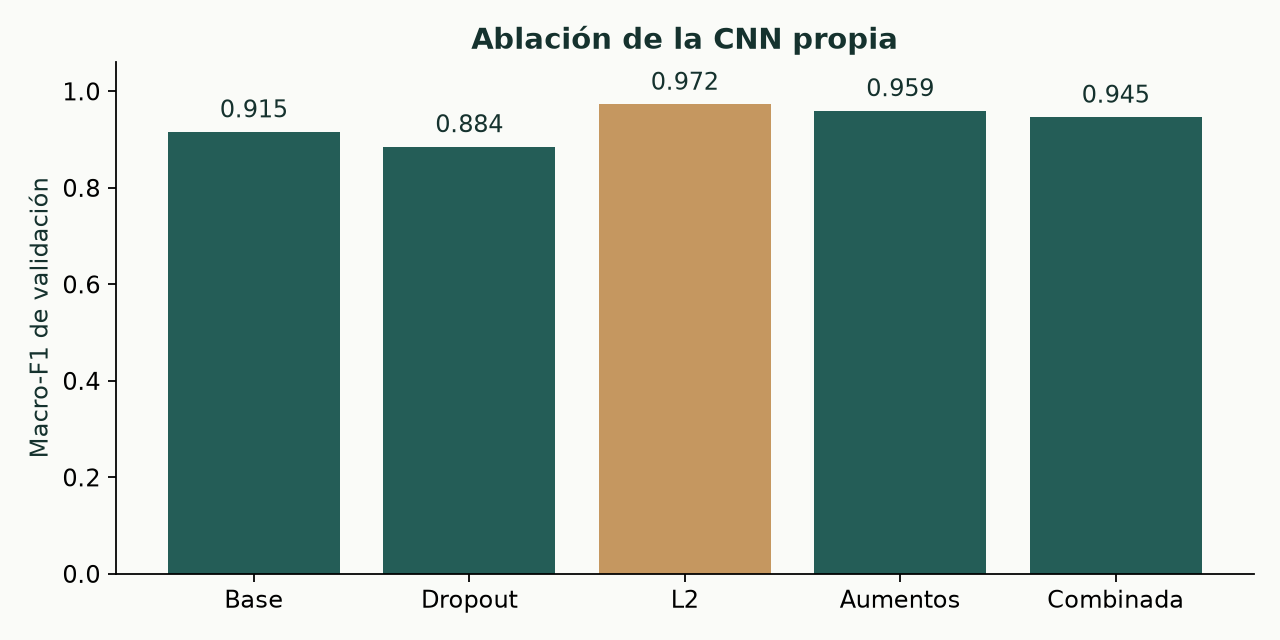

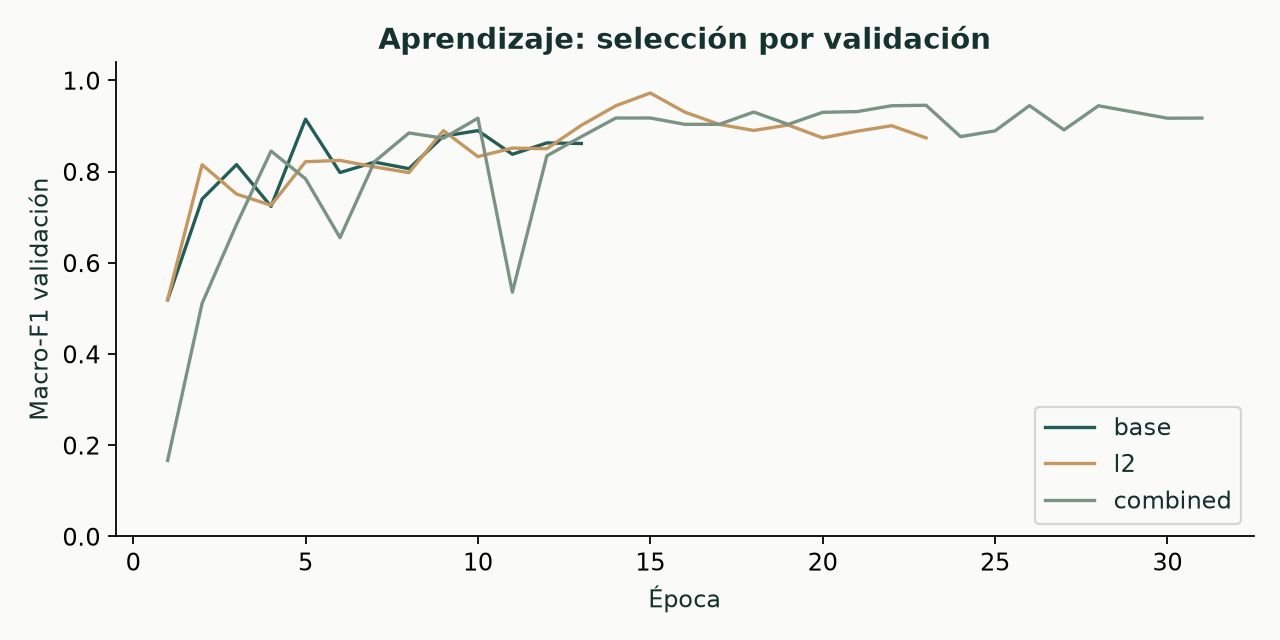

In [4]:
comparison=json.loads((ROOT/"results/classification/comparison.json").read_text())
for r in comparison: print(r["variant"], "mejor época",r["best_epoch"],"F1 val",round(r["validation"]["macro_f1"],4))
show(ROOT/"results/figures/ablation.png")
show(ROOT/"results/figures/learning.png")


## 3. Evaluar el error, no solo el promedio

La CNN seleccionada cayó a 52/72. La transferencia obtuvo 67/72 en un diagnóstico ya abierto; cinco manuscritos se sugirieron como impresos. CV sirve para selección y no equivale a una prueba externa.

CV agregado: {'n': 408, 'accuracy': 0.9534313725490197, 'macro_f1': 0.9531318103098251, 'confusion_matrix': [[131, 5, 0], [9, 123, 4], [0, 1, 135]], 'classes': {'documento_impreso': {'precision': 0.9357142857142857, 'recall': 0.9632352941176471, 'f1': 0.9492753623188407, 'support': 136}, 'manuscrito': {'precision': 0.9534883720930233, 'recall': 0.9044117647058824, 'f1': 0.9283018867924528, 'support': 136}, 'pintura': {'precision': 0.9712230215827338, 'recall': 0.9926470588235294, 'f1': 0.9818181818181818, 'support': 136}}}
Diagnóstico secundario: {'n': 72, 'accuracy': 0.9305555555555556, 'macro_f1': 0.9297937691970163, 'confusion_matrix': [[24, 0, 0], [5, 19, 0], [0, 0, 24]], 'classes': {'documento_impreso': {'precision': 0.8275862068965517, 'recall': 1.0, 'f1': 0.9056603773584906, 'support': 24}, 'manuscrito': {'precision': 1.0, 'recall': 0.7916666666666666, 'f1': 0.8837209302325582, 'support': 24}, 'pintura': {'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'support': 24}}}


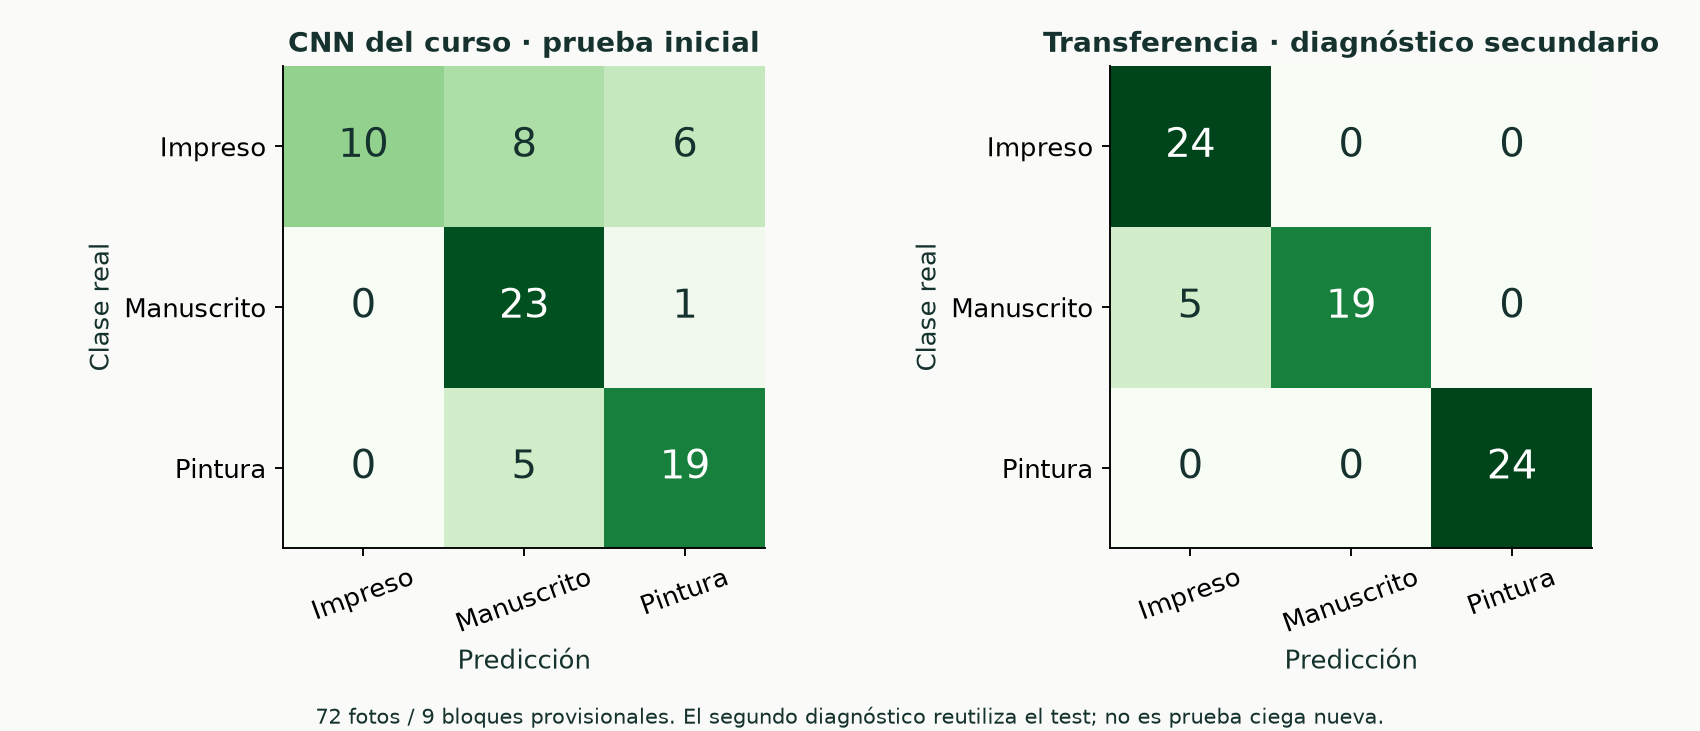

In [5]:
result=json.loads((ROOT/"results/transfer/evaluation.json").read_text())
sel=next(x for x in result["comparisons"] if x["C"]==result["selected_C"])
print("CV agregado:",sel["out_of_fold"])
print("Diagnóstico secundario:",result["secondary_test"])
show(ROOT/"results/figures/confusion.png")


Latencia: {'median': 32.42299999692477, 'p95': 38.571080009569414, 'scope': 'classification only, warm CPU 4 threads; no image decoding'}
Errores: [{'image_id': 'I0267', 'group_id': 'MAN012', 'true': 'manuscrito', 'predicted': 'documento_impreso', 'max_score': 0.5134364366531372}, {'image_id': 'I0290', 'group_id': 'MAN014', 'true': 'manuscrito', 'predicted': 'documento_impreso', 'max_score': 0.5258776545524597}, {'image_id': 'I0291', 'group_id': 'MAN014', 'true': 'manuscrito', 'predicted': 'documento_impreso', 'max_score': 0.5825766921043396}, {'image_id': 'I0295', 'group_id': 'MAN014', 'true': 'manuscrito', 'predicted': 'documento_impreso', 'max_score': 0.8320737481117249}, {'image_id': 'I0296', 'group_id': 'MAN014', 'true': 'manuscrito', 'predicted': 'documento_impreso', 'max_score': 0.5116438269615173}]


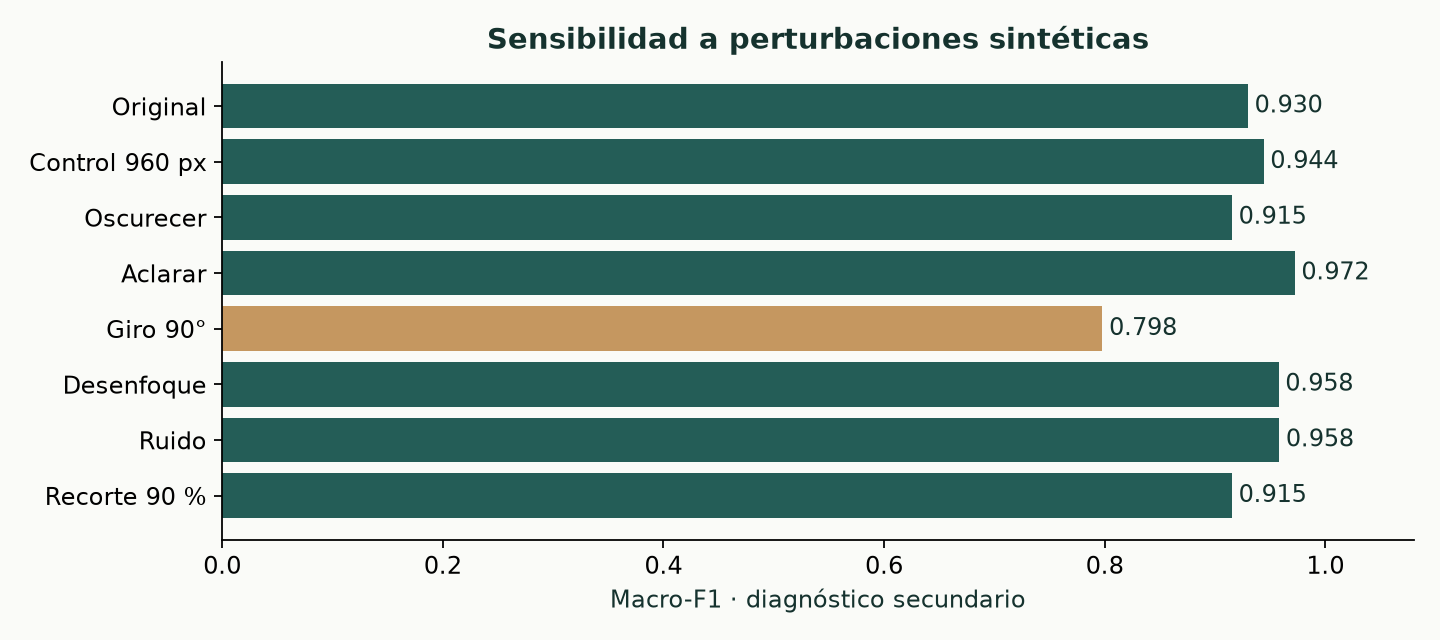

In [6]:
robust=json.loads((ROOT/"results/robustness/evaluation.json").read_text())
print("Latencia:",robust["latency_ms"])
print("Errores:",robust["errors"])
show(ROOT/"results/figures/robustness.png")


## 4. Perspectiva y coordenadas

Una homografía representa un plano. Esquinas normalizadas se proyectan sobre RGB original; una proporción conocida es información adicional. Este ejemplo verifica correspondencias, no calidad de detección.

In [7]:
ref=page()
corners=np.array([[.08,.10],[.90,.04],[.95,.90],[.12,.94]],np.float32)
warped,H=rectify(ref,corners,aspect=.75)
projected=cv2.perspectiveTransform((corners*np.array([599,799],np.float32))[None],H)[0]
expected=np.float32([[0,0],[warped.shape[1]-1,0],[warped.shape[1]-1,warped.shape[0]-1],[0,warped.shape[0]-1]])
print("Error máximo de correspondencia:",float(np.max(np.abs(projected-expected))))
print("Matriz H:\n",H)


Error máximo de correspondencia: 6.911897947438697e-14
Matriz H:
 [[ 1.05533938e+00 -3.76749668e-02 -4.75616313e+01]
 [ 9.92234646e-02  1.01661612e+00 -8.59824175e+01]
 [ 5.10941784e-05  1.42227124e-05  1.00000000e+00]]


## 5. Filtros espaciales y FFT

La inversión FFT conserva el signo: tomar el valor absoluto de una respuesta derivativa cambia el filtro. Los bordes periódicos requieren cuidado. Este high-boost es una comparación didáctica; el filtro operativo es espacial y reversible.

In [8]:
from skimage.metrics import structural_similarity, peak_signal_noise_ratio
clean=page(); blurred=cv2.GaussianBlur(clean,(0,0),1.4)
neutral=dict(illumination=0,contrast=0,denoise=0,sharpness=0,binary="off",background="gaussian")
spatial,_=enhance(blurred,{**neutral,"sharpness":.5},"documento_impreso")
frequency=fft_highboost(blurred)
for name,a in [("degradada",blurred),("espacial",spatial),("FFT",frequency)]:
    print(name,"PSNR",round(float(peak_signal_noise_ratio(clean,a,data_range=255)),3),"SSIM",round(float(structural_similarity(clean,a,data_range=255,channel_axis=2)),4))


degradada PSNR 19.599 SSIM 0.8351
espacial PSNR 19.83 SSIM 0.8448
FFT PSNR 20.068 SSIM 0.8534


## 6. Referencia alineada y control sin mejora

El caso limpio demuestra por qué no debe aplicarse nitidez por obligación. En el uso habitual no hay referencia verdadera: la aplicación no calcula SSIM/PSNR frente a la fotografía de entrada como si fuera una verdad restaurada.

Saved 28 quality comparisons to C:\Users\pipef\Documents\Codex\2026-11-18\necesito-realizar-mi-proyecto-final-de\outputs\palimpsesto\results\quality
Sin mejoras: píxeles idénticos


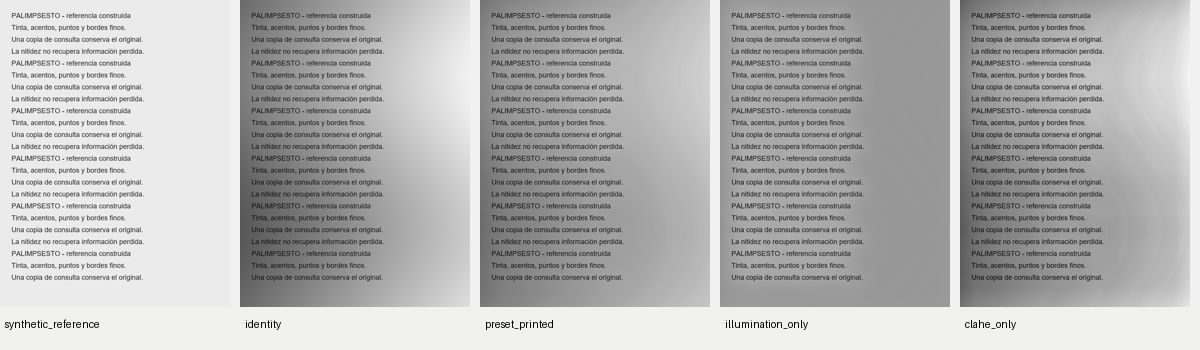

In [9]:
import benchmark_quality
benchmark_quality.main()
show(ROOT/"results/quality/comparison.png")
unchanged,_=enhance(clean,neutral,"pintura")
assert np.array_equal(clean,unchanged)
print("Sin mejoras: píxeles idénticos")


## 7. Inferencia y exportación de principio a fin

La prueba de funciones emplea un stub para aislar software; el siguiente registro corresponde a nueve casos con ambos modelos reales. La aceptación visual humana permanece pendiente.

In [10]:
integration=json.loads((ROOT/"results/integration/real_pipeline.json").read_text())
print(integration["models"],"; recorridos válidos:",integration["passed"])
for r in integration["cases"]:print(r["image_id"],r["true_class"],"sugerencia",r["suggested_class"],"exportación",r["export_valid"])


real checkpoint inference, no stub ; recorridos válidos: 9
I0018 documento_impreso sugerencia documento_impreso exportación True
I0066 documento_impreso sugerencia documento_impreso exportación True
I0162 documento_impreso sugerencia documento_impreso exportación True
I0226 manuscrito sugerencia manuscrito exportación True
I0266 manuscrito sugerencia manuscrito exportación True
I0290 manuscrito sugerencia documento_impreso exportación True
I0050 pintura sugerencia pintura exportación True
I0362 pintura sugerencia pintura exportación True
I0490 pintura sugerencia pintura exportación True


## 8. Cierre científico y humano

Revisar IDs físicos; reservar piezas nuevas que no haya visto ningún modelo; congelar pesos antes de evaluarlas; anotar esquinas y conservación de detalles; realizar usabilidad con personas reales. Consultar el informe y la guía de sustentación. Fuentes: [homografía OpenCV](https://docs.opencv.org/4.x/d9/dab/tutorial_homography.html), [transferencia PyTorch](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html), [métricas scikit-image](https://scikit-image.org/docs/stable/api/skimage.metrics.html).